# Why can a thin layer change concrete pumping?

*Python for Engineers: Case Studies from Calculator to Simulation* · Notebook 21 · Yanwei Wang

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/python-for-engineers-case-studies/blob/main/notebooks/21_Concrete_Pumping_Two_Layer_Model.ipynb)

**Audience:** first-year engineering students. No fluid mechanics or concrete technology is assumed.

Imagine moving freshly mixed concrete from a truck through a long hose to a placement point. Before it hardens, concrete is a concentrated mixture that can flow under sufficient force. The pump must supply enough **pressure** to deliver a desired volume each hour. A very thin, less aggregate-rich region can form beside the pipe wall. Its presence changes the flow throughout the pipe, even though it occupies little of the cross-section.

**Our question:** At a given pressure loss, how much does a thin lubrication layer change the concrete flow rate? We will also reverse the question: what pressure loss is needed to deliver a chosen flow rate?

This is a guided, original Python implementation of ideas from **B. Zhaidarbek, A. Tleubek, G. Berdibek, and Y. Wang, “Analytical predictions of concrete pumping: Extending the Khatib–Khayat model to Herschel–Bulkley and modified Bingham fluids,” *Cement and Concrete Research* 163 (2023) 107035**, [doi:10.1016/j.cemconres.2022.107035](https://doi.org/10.1016/j.cemconres.2022.107035). We cite the paper's equation and figure numbers at the relevant steps. The numerical values below are *illustrative parameter choices from its figures*, not field measurements or a pump specification.

**How to use this notebook.** Read each explanation, predict the next result, run the cell, and compare your prediction. Run cells from top to bottom in a fresh kernel. Required packages: NumPy and Matplotlib. Python 3.10 or newer is recommended. Every executable line is explained beside it. The notebook saves each original figure in `figures_concrete_pumping/` as SVG and 300 dpi PNG, while the executed notebook retains the displayed figures.

<!-- pfe-study-guide -->
## Study guide

| | |
|---|---|
| **Status** | Optional · Extensions |
| **Time** | about 50 min of reading |
| **Before this** | Functions and plotting (notebooks 02 and 05); the ideas of pressure and shear stress. |
| **Essential** | Sections 1–10 and 12. |
| **Optional on a first reading** | Sections 11, 13 and 14. |
| **Next** | 22, the same pipe-flow ideas for a polymer melt. |

**You have understood this notebook if you can, without looking back:**

1. Explain why the shear stress in a pipe grows linearly from the centre to the wall.
2. Locate the solid-like plug from the yield stress.
3. Explain how a thin lubrication layer near the wall changes the flow rate.
4. Use the code in reverse to find the pressure needed for a target flow rate.
5. State one thing the model does not calculate.

**Not expected of you:** The flow-rate integrals: the notebook checks them for you.

*The comment on every code line is a reading aid. In your own programs, comment the reasons and the non-obvious steps.*

## 1. What is moving, and what do we measure?

The material in this model has two **concentric regions**: a central concrete region and a thin outer *lubrication layer* (LL). This is a model of fresh concrete flowing in a straight circular pipe, rather than a claim that the real material has a perfectly sharp boundary.

| Name | Symbol | Meaning | SI unit |
| --- | --- | --- | --- |
| Pipe radius | $R$ | Distance from pipe center to wall | m |
| Layer thickness | $\ell$ | Width of outer LL region | m |
| Interface radius | $a=R-\ell$ | Boundary between the two model regions | m |
| Pipe length | $L$ | Distance along the pipe | m |
| Pressure loss | $\Delta\mathcal P$ | Drop in modified pressure over $L$ | Pa |
| Pressure gradient | $G=\Delta\mathcal P/L$ | Pressure loss per length | Pa/m |
| Axial speed | $u(r)$ | Speed at radial position $r$ | m/s |
| Volume flow rate | $Q$ | Volume delivered per second | m³/s |
| Shear stress | $\tau(r)$ | Tangential force per unit area | Pa |
| Shear rate | $\dot\gamma(r)$ | How quickly speed changes across radius | 1/s |

Here $1\ \mathrm{Pa}=1\ \mathrm{N/m^2}$ and $1\ \mathrm{kPa}=1000\ \mathrm{Pa}$. One hour contains 3600 s. For a horizontal pipe, $\Delta\mathcal P$ is the usual inlet-to-outlet static pressure difference. An uphill pipe needs an additional gravity contribution, discussed near the end.

A circular cross-section has area $A=\pi R^2$. **Warm-up, by hand:** if *everywhere* the speed were $0.10$ m/s in a pipe of radius $0.0625$ m, then $Q=A u$. Predict the result in m³/h. Real pipe flow generally does not have uniform speed; this calculation teaches the units.

In [1]:
# Import numerical arrays and mathematical functions for the calculations below.
import numpy as np
# NumPy 2.0 renamed np.trapz to np.trapezoid; this keeps the notebook working on NumPy 1.x as well.
if not hasattr(np, 'trapezoid'):
    # Point the new name at the old function so later np.trapezoid calls work on any NumPy version.
    np.trapezoid = np.trapz
# Import Matplotlib's plotting interface for diagrams and scientific figures.
import matplotlib.pyplot as plt
# Import circle patches to draw a simple two-region pipe schematic.
from matplotlib.patches import Circle
# Import Path so rerunning the notebook creates a predictable figure folder.
from pathlib import Path
# Set readable typography and a restrained visual style for all original figures.
plt.rcParams.update({"font.size": 10, "axes.titlesize": 12, "axes.labelsize": 10, "svg.fonttype": "none", "figure.dpi": 125})
# Name the output folder relative to the notebook's current working directory.
figure_dir = Path("figures_concrete_pumping")
# Create the folder if necessary, including missing parents, without an error on reruns.
figure_dir.mkdir(parents=True, exist_ok=True)
# Keep a consistent, color-blind-friendly set of curve colors in one dictionary.
palette = {"ink": "#263442", "blue": "#2166AC", "teal": "#008A80", "orange": "#D57B19", "rose": "#B54C68", "grey": "#667685"}
# Define a helper that saves each figure before displaying it in the notebook.
def finish_figure(fig, name):
    '''Save a vector image and a high-resolution raster fallback, then display.'''
    # Save editable vector geometry and selectable plot labels when possible.
    fig.savefig(figure_dir / f"{name}.svg", bbox_inches="tight")
    # Save a crisp image for software that does not display SVG well.
    fig.savefig(figure_dir / f"{name}.png", dpi=300, bbox_inches="tight")
    # Display this figure in the executed notebook and release its resources.
    plt.show()

In [2]:
# Use the inside radius reported in the paper's illustrative figure settings, in metres.
pipe_radius_m = 0.0625
# Choose an easy, uniform example speed in metres per second for the hand check.
example_speed_m_s = 0.10
# Calculate area in square metres from the radius in metres.
area_m2 = np.pi * pipe_radius_m**2
# Multiply area by speed to obtain volume per second, in cubic metres per second.
uniform_q_m3_s = area_m2 * example_speed_m_s
# Convert from cubic metres per second to cubic metres per hour.
uniform_q_m3_h = uniform_q_m3_s * 3600.0
# Show the student the units and the expected hand-calculation result.
print(f"A = {area_m2:.5f} m²; Q = {uniform_q_m3_h:.2f} m³/h")
# Check that converting hours back to seconds recovers the original flow rate.
assert np.isclose(uniform_q_m3_h / 3600.0, uniform_q_m3_s)

A = 0.01227 m²; Q = 4.42 m³/h


## 2. Why does pressure create shear stress?

Picture an imaginary cylinder of fluid of radius $r$ and length $L$ inside the pipe. The pressure difference pushes on its end with force $\pi r^2\Delta\mathcal P$. The surrounding fluid exerts an opposing tangential force $2\pi r L\tau(r)$ on its side. Balancing these forces gives

$$\pi r^2\Delta\mathcal P=2\pi rL\tau(r),\qquad
\boxed{\tau(r)=\frac{Gr}{2}},\qquad G=\frac{\Delta\mathcal P}{L}.$$

This is Eq. (8) of the paper. Stress starts at zero on the centerline and reaches $\tau_{\rm wall}=GR/2$ at the wall. Check units: $(\mathrm{Pa/m})\,\mathrm{m}=\mathrm{Pa}$. **Predict:** at $G=60$ kPa/m and $R=62.5$ mm, is the wall stress closer to $20$ Pa or $2000$ Pa?

In [3]:
# Use the illustrative gradient from the paper's velocity-profile figure, in Pa/m.
pressure_gradient_pa_m = 60_000.0
# Convert an illustrative layer thickness of 1.5 mm to metres.
layer_thickness_m = 0.0015
# Calculate where the model switches from bulk concrete to the outer layer.
interface_radius_m = pipe_radius_m - layer_thickness_m
# Apply the force balance at the outer wall to find its shear stress in pascals.
wall_stress_pa = pressure_gradient_pa_m * pipe_radius_m / 2.0
# Apply the same balance at the interface between the two material regions.
interface_stress_pa = pressure_gradient_pa_m * interface_radius_m / 2.0
# Print values with their units to compare against the hand prediction.
print(f"Interface stress = {interface_stress_pa:.1f} Pa; wall stress = {wall_stress_pa:.1f} Pa")
# Independently check pressure force against opposing shear force on a 1 m test cylinder.
assert np.isclose(np.pi * pipe_radius_m**2 * pressure_gradient_pa_m, 2 * np.pi * pipe_radius_m * wall_stress_pa)

Interface stress = 1830.0 Pa; wall stress = 1875.0 Pa


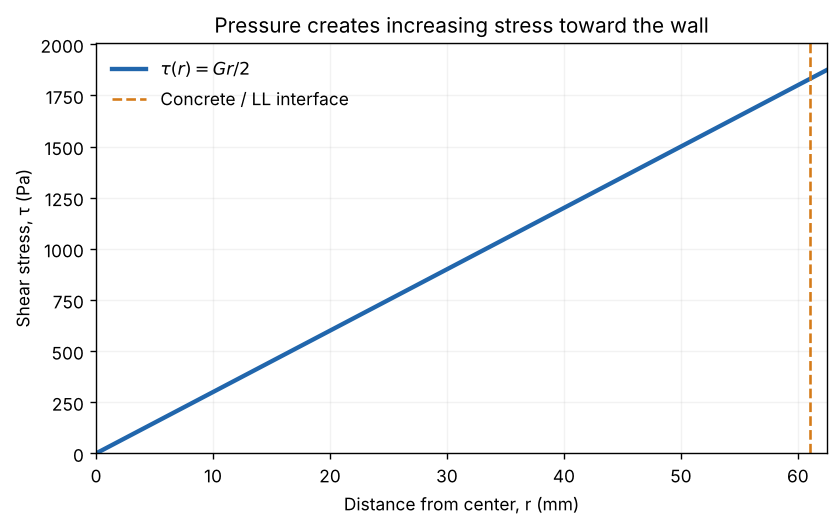

In [4]:
# Make radial positions from the centerline to the wall for a stress diagram.
stress_r_m = np.linspace(0.0, pipe_radius_m, 400)
# Compute the shear stress along that radius using the force balance.
stress_pa = pressure_gradient_pa_m * stress_r_m / 2.0
# Make a compact figure whose axes state both variable and unit.
fig, ax = plt.subplots(figsize=(6.6, 4.1), layout="constrained")
# Draw the predicted linear stress profile in an accessible dark blue.
ax.plot(1000 * stress_r_m, stress_pa, color=palette["blue"], lw=2.5, label=r"$\tau(r)=Gr/2$")
# Mark the material interface without implying a jump in the stress itself.
ax.axvline(1000 * interface_radius_m, color=palette["orange"], ls="--", lw=1.5, label="Concrete / LL interface")
# Mark the centerline and wall with the natural radius limits.
ax.set(xlim=(0, 1000 * pipe_radius_m), ylim=(0, 1.07 * wall_stress_pa), xlabel="Distance from center, r (mm)", ylabel="Shear stress, τ (Pa)", title="Pressure creates increasing stress toward the wall")
# Use a light grid that supports reading without dominating the data.
ax.grid(alpha=0.16)
# Place the legend away from the key wall-stress value.
ax.legend(frameon=False, loc="upper left")
# Export and embed the complete, labeled stress diagram.
finish_figure(fig, "01_radial_stress")

**Figure 1.** Stress varies smoothly through both regions because the same pressure force balance acts across the radius. The *material response to that stress* can change abruptly at the idealized interface.

## 3. How does fresh concrete respond to stress?

A **yield stress**, $\tau_0$, is a threshold: below it, this simplified material does not shear. A region may still move as a solid-like **plug** if neighboring material shears and carries it along. Above the threshold, the **Herschel–Bulkley (HB) model** used in Eq. (3) of the paper is

$$\tau=\tau_0+K\dot\gamma^{\,n},\qquad
\dot\gamma=\left(\frac{\tau-\tau_0}{K}\right)^{1/n}\quad (\tau>\tau_0).$$

Below yield, set $\dot\gamma=0$. Here $K$ has units **Pa·s$^n$** and $n$ is dimensionless. $n=1$ gives the linear Bingham law with $K$ equal to plastic viscosity (Pa·s); $n>1$ thickens relative to that law and $n<1$ thins. These terms describe how additional stress grows with shear rate; they do **not** say that concrete itself expands or shrinks.

The paper's illustrative parameters below describe two separate model materials. The layer is much easier to shear. Its 1.5 mm thickness is only 2.4% of the 62.5 mm pipe radius. First predict whether such a small thickness could still have a substantial effect on flow.

In [5]:
# Record the paper's illustrative bulk-concrete yield stress in pascals.
core_hb = {"tau0_pa": 30.0, "K_pa_s_n": 50.0, "n": 1.05}
# Record the corresponding illustrative lubrication-layer material parameters.
layer_hb = {"tau0_pa": 1.0, "K_pa_s_n": 5.0, "n": 1.05}
# Calculate the fraction of pipe radius occupied by the modeled outer layer.
relative_thickness = layer_thickness_m / pipe_radius_m
# Show the geometric fraction as a percent, without confusing it with an area fraction.
print(f"Layer thickness / pipe radius = {100 * relative_thickness:.1f}%")
# Check the model has a nonempty concrete region and a nonempty layer.
assert 0.0 < layer_thickness_m < pipe_radius_m

Layer thickness / pipe radius = 2.4%


In [6]:
# Define the forward HB law for plotting stress as a function of shear rate.
def hb_stress_pa(shear_rate_s_inv, material):
    '''Return HB shear stress (Pa) for nonnegative shear rates (1/s).'''
    # Convert scalar or list input into a numerical array for one consistent rule.
    rate = np.asarray(shear_rate_s_inv, dtype=float)
    # Evaluate the paper's yield-stress-plus-power-law expression in pascals.
    return material["tau0_pa"] + material["K_pa_s_n"] * rate**material["n"]

# Define the inverse law used when pressure determines stress first.
def hb_shear_rate_s_inv(stress_pa_value, material):
    '''Return shear rate (1/s) at imposed stress (Pa); zero below yield.'''
    # Allow a scalar or an array of imposed stresses without changing the formula.
    stress = np.asarray(stress_pa_value, dtype=float)
    # Clip negative excess stress to zero so an unyielded location has zero shear rate.
    excess_pa = np.maximum(stress - material["tau0_pa"], 0.0)
    # Invert the increasing HB stress law to obtain local shear rate in 1/s.
    return (excess_pa / material["K_pa_s_n"]) ** (1.0 / material["n"])

In [7]:
# Select the concrete yield stress as a hand-checkable imposed stress.
test_yield_pa = core_hb["tau0_pa"]
# At the yield threshold, the inverse law must give no shear.
rate_at_yield = hb_shear_rate_s_inv(test_yield_pa, core_hb)
# One extra K in pascals corresponds to exactly one inverse second in this unit system.
test_one_per_s_pa = core_hb["tau0_pa"] + core_hb["K_pa_s_n"]
# Check that the inverse and forward expressions agree at 1 per second.
rate_one_per_s = hb_shear_rate_s_inv(test_one_per_s_pa, core_hb)
# Display the two predictable examples before using larger numerical arrays.
print(f"At τ = τ₀: γ̇ = {rate_at_yield:.1f} 1/s; at τ = τ₀ + K: γ̇ = {rate_one_per_s:.1f} 1/s")
# Detect an implementation that mistakenly shears material below yield.
assert hb_shear_rate_s_inv(test_yield_pa - 1.0, core_hb) == 0.0
# Verify a known inverse value without repeating the same array operation.
assert np.isclose(rate_one_per_s, 1.0)

At τ = τ₀: γ̇ = 0.0 1/s; at τ = τ₀ + K: γ̇ = 1.0 1/s


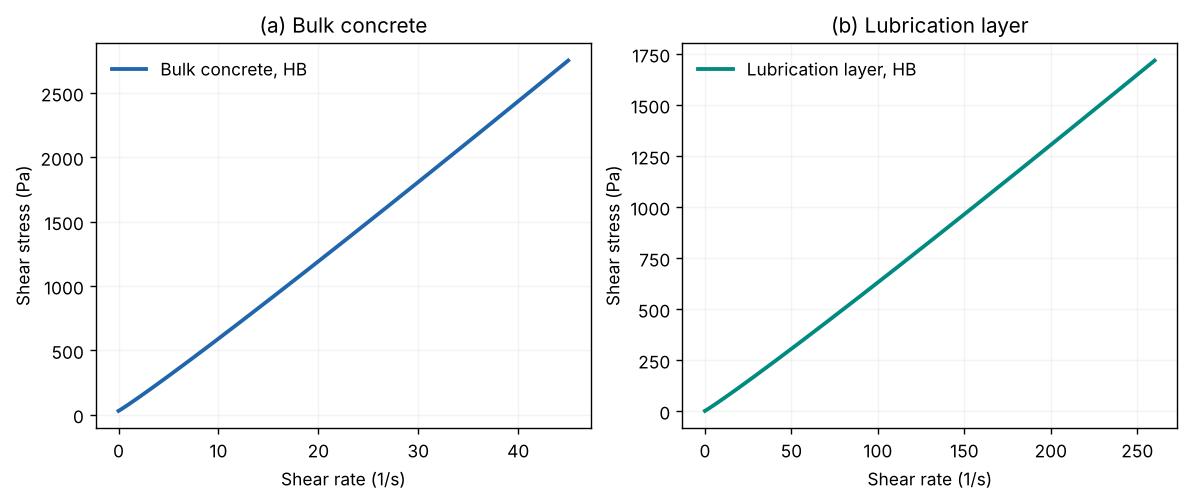

In [8]:
# Sample a practical illustrative shear-rate range for the bulk material.
core_rates = np.linspace(0.0, 45.0, 400)
# Sample a wider shear-rate range for the easier-shearing lubrication layer.
layer_rates = np.linspace(0.0, 260.0, 400)
# Create separate panels because the two materials have different useful scales.
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9), layout="constrained")
# Draw the HB bulk stress for the paper's illustrative parameter set.
axes[0].plot(core_rates, hb_stress_pa(core_rates, core_hb), color=palette["blue"], lw=2.2, label="Bulk concrete, HB")
# Draw the HB layer stress for the paper's illustrative parameter set.
axes[1].plot(layer_rates, hb_stress_pa(layer_rates, layer_hb), color=palette["teal"], lw=2.2, label="Lubrication layer, HB")
# Explain the left panel's quantity and units directly on its axes.
axes[0].set(xlabel="Shear rate (1/s)", ylabel="Shear stress (Pa)", title="(a) Bulk concrete")
# Explain the right panel's quantity and units directly on its axes.
axes[1].set(xlabel="Shear rate (1/s)", ylabel="Shear stress (Pa)", title="(b) Lubrication layer")
# Apply restrained grids and legends to both panels in the same way.
for ax in axes:
    # Keep grid lines faint enough that the data remain easy to follow.
    ax.grid(alpha=0.14)
    # Identify each region's curve without a large legend box.
    ax.legend(frameon=False)
# Save and show this new plotting-code illustration of Eq. (3).
finish_figure(fig, "02_hb_material_laws")

**Figure 2.** The outer material has a smaller stress at the same shear rate for these illustrative choices. The plotted curves represent a constitutive *assumption*, not measurements supplied with this notebook.

## 4. Locate the solid-like central plug

The stress increases from the center toward the wall. The bulk first begins to shear where $Gr/2=\tau_{0,C}$. Solving this one-line equation gives the paper's Eq. (10):

$$r_{\rm plug}=\frac{2\tau_{0,C}}{G}.$$

If $r_{\rm plug}<a=R-\ell$, the core has a central plug and an outer shearing ring (**Case II**). If $r_{\rm plug}\ge a$, the whole core is a moving plug (**Case I**), provided the layer can shear. The paper associates these model patterns with illustrative SCC- and CVC-like behaviors; the classification is by **calculated radii**, not a promise about a particular concrete mix. **Predict** which case follows for $\tau_{0,C}=30$ Pa and for $2000$ Pa at the same $G$.

In [9]:
# Collect a low and a high illustrative yield stress for the same pipe.
candidate_yield_pa = [30.0, 2000.0]
# Compare each predicted plug radius with the actual concrete-region radius.
for yield_pa in candidate_yield_pa:
    # Solve the threshold-stress equation for the plug radius, in metres.
    plug_radius_m = 2.0 * yield_pa / pressure_gradient_pa_m
    # Mark the core as fully plugged when the threshold lies outside it.
    case = "Case I: entire core plugs" if plug_radius_m >= interface_radius_m else "Case II: core also shears"
    # Report the radius in millimetres so the comparison is easy to see.
    print(f"τ₀,C = {yield_pa:.0f} Pa: r_plug = {1000 * plug_radius_m:.2f} mm; {case}")
# Catch a unit conversion or inequality mistake in the two regimes.
assert 2 * candidate_yield_pa[0] / pressure_gradient_pa_m < interface_radius_m < 2 * candidate_yield_pa[1] / pressure_gradient_pa_m

τ₀,C = 30 Pa: r_plug = 1.00 mm; Case II: core also shears
τ₀,C = 2000 Pa: r_plug = 66.67 mm; Case I: entire core plugs


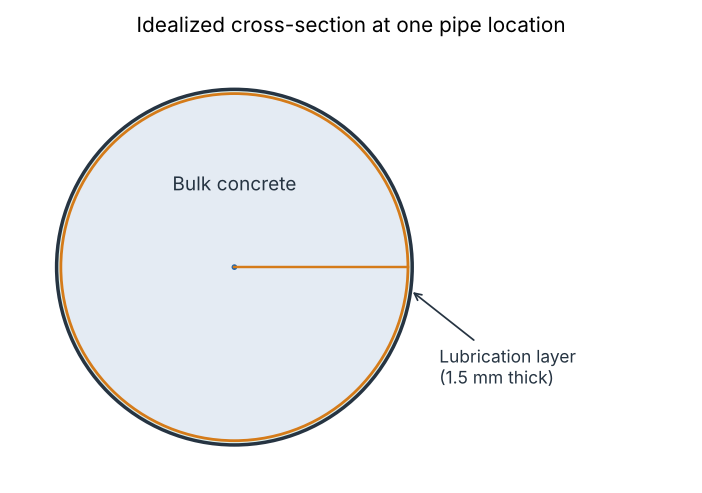

In [10]:
# Build a top-down cross-section sketch with the same geometric proportions as the model.
fig, ax = plt.subplots(figsize=(5.5, 5.1), layout="constrained")
# Draw the outer lubrication region as a pale disk bounded by the pipe wall.
ax.add_patch(Circle((0, 0), pipe_radius_m, facecolor="#DCEEEB", edgecolor=palette["ink"], lw=2.0))
# Cover the center with the concrete-region disk to leave an annular layer.
ax.add_patch(Circle((0, 0), interface_radius_m, facecolor="#E4EBF3", edgecolor=palette["orange"], lw=1.6))
# Mark the small central plug for the 30 Pa illustrative material.
ax.add_patch(Circle((0, 0), 2 * core_hb["tau0_pa"] / pressure_gradient_pa_m, facecolor=palette["blue"], edgecolor="none"))
# Mark the core/LL interface on the horizontal midline.
ax.plot([0, interface_radius_m], [0, 0], color=palette["orange"], lw=1.4)
# Place the narrow layer's label outside the pipe so its text remains readable.
ax.annotate("Lubrication layer\n(1.5 mm thick)", xy=(pipe_radius_m - layer_thickness_m / 2, -0.008), xytext=(0.072, -0.035), arrowprops={"arrowstyle": "->", "color": palette["ink"]}, color=palette["ink"], ha="left", va="center")
# Label the much larger bulk region on an unobstructed part of the disk.
ax.text(0, 0.027, "Bulk concrete", ha="center", color=palette["ink"], fontsize=11)
# Use identical physical scale horizontally and vertically to preserve the circles.
ax.set_aspect("equal")
# Leave white space to the right for the external layer label.
ax.set(xlim=(-0.078, 0.16), ylim=(-0.075, 0.079), title="Idealized cross-section at one pipe location")
# Remove ticks and frame because the geometry is a labeled schematic.
ax.axis("off")
# Save and display the original two-region diagram.
finish_figure(fig, "03_two_region_cross_section")

**Figure 3.** This is a schematic model: its narrow green annulus occupies a small area, but it sits where the pressure-driven shear stress is greatest. The blue plug is much smaller for the 30 Pa bulk example; the drawing does not represent individual aggregate particles.

## 5. First solve a one-material pipe

We need a simple building block before combining two materials. Define $Q_{\rm HP}(\text{material},b,G)$ as the flow rate through a *single-material pipe* of radius $b$ with zero speed at its wall. For a Newtonian material of viscosity $\mu$, the familiar special case is $Q=\pi Gb^4/(8\mu)$. You can treat this as a check, even without deriving it.

For an HB material, Eqs. (15)–(16) of the paper give a compact result. Write $w=Gb/2$, $t=\tau_0/w$, and $u_{\rm plug}=\frac{nb}{n+1}(w/K)^{1/n}(1-t)^{(n+1)/n}$. For $w>\tau_0$,

$$Q_{\rm HP}=\pi b^2u_{\rm plug}\left[1-\frac{2n}{3n+1}\left(1+\frac{n}{2n+1}t\right)(1-t)\right].$$

For $w\le\tau_0$, the entire single-material pipe is unyielded and $Q_{\rm HP}=0$. The variable $u_{\rm plug}$ is the speed of the central plateau in this *single-material, zero-wall-speed* calculation. We will test the formula against an independently computed integral rather than trusting its appearance.

In [11]:
# Implement the simple Newtonian limit as an independent reference.
def newtonian_flow_m3_s(radius_m, gradient_pa_m, viscosity_pa_s):
    '''Return laminar Newtonian pipe flow rate in m³/s.'''
    # Evaluate the classical radius-to-the-fourth-power pipe formula.
    return np.pi * gradient_pa_m * radius_m**4 / (8.0 * viscosity_pa_s)

# Implement the paper's closed HB single-material pipe result.
def hb_pipe_flow_m3_s(radius_m, gradient_pa_m, material):
    '''Return Eq. (15) HB flow rate for one zero-wall-speed pipe (m³/s).'''
    # Calculate the maximum stress attained at the boundary of this pipe.
    boundary_stress_pa = gradient_pa_m * radius_m / 2.0
    # If the maximum stress stays below yield, no part of this pipe shears.
    if boundary_stress_pa <= material["tau0_pa"] or radius_m == 0.0:
        # Return exactly zero so downstream two-layer limits behave cleanly.
        return 0.0
    # Read the dimensionless HB exponent once for clarity in the formula.
    exponent = material["n"]
    # Form the dimensionless ratio of yield stress to boundary stress.
    yield_fraction = material["tau0_pa"] / boundary_stress_pa
    # Calculate the center's plug speed for this single-material pipe.
    plug_speed_m_s = exponent * radius_m / (exponent + 1.0) * (boundary_stress_pa / material["K_pa_s_n"]) ** (1.0 / exponent) * (1.0 - yield_fraction) ** ((exponent + 1.0) / exponent)
    # Apply the dimensionless factor in the paper's Eq. (15).
    shape_factor = 1.0 - 2.0 * exponent / (3.0 * exponent + 1.0) * (1.0 + exponent * yield_fraction / (2.0 * exponent + 1.0)) * (1.0 - yield_fraction)
    # Multiply cross-section, plateau speed, and shape factor to get m³/s.
    return np.pi * radius_m**2 * plug_speed_m_s * shape_factor

In [12]:
# Build the zero-yield, n=1 HB limit that must behave as a Newtonian fluid.
newtonian_as_hb = {"tau0_pa": 0.0, "K_pa_s_n": 5.0, "n": 1.0}
# Evaluate the paper's HB formula with those special parameters.
hb_limit_q = hb_pipe_flow_m3_s(pipe_radius_m, pressure_gradient_pa_m, newtonian_as_hb)
# Independently calculate the classical result using the Newtonian formula.
newtonian_q = newtonian_flow_m3_s(pipe_radius_m, pressure_gradient_pa_m, 5.0)
# Print both limits in m³/h, which is a familiar delivery-rate unit.
print(f"HB special case: {hb_limit_q * 3600:.6f} m³/h; Newtonian formula: {newtonian_q * 3600:.6f} m³/h")
# Detect an algebraic coefficient error in the HB closed form.
assert np.isclose(hb_limit_q, newtonian_q, rtol=1e-12)
# Check the separate unyielded limiting case rather than allowing negative powers.
assert hb_pipe_flow_m3_s(pipe_radius_m, 100.0, core_hb) == 0.0

HB special case: 258.859258 m³/h; Newtonian formula: 258.859258 m³/h


In [13]:
# Turn the HB material into an exactly linear Bingham model by choosing n = 1.
bingham_check = {"tau0_pa": 30.0, "K_pa_s_n": 50.0, "n": 1.0}
# Evaluate the paper's HB pipe function at the representative gradient.
hb_as_bingham_q = hb_pipe_flow_m3_s(pipe_radius_m, pressure_gradient_pa_m, bingham_check)
# Form the Buckingham–Reiner yield ratio independently from wall stress.
bingham_ratio = bingham_check["tau0_pa"] / wall_stress_pa
# Evaluate the separate Bingham formula, Eq. (14) of the paper.
bingham_reference_q = newtonian_flow_m3_s(pipe_radius_m, pressure_gradient_pa_m, 50.0) * (1.0 - 4.0 * bingham_ratio / 3.0 + bingham_ratio**4 / 3.0)
# Show the result in practical delivery-rate units for a direct comparison.
print(f"HB n=1: {hb_as_bingham_q * 3600:.6f}; Bingham reference: {bingham_reference_q * 3600:.6f} m³/h")
# Catch mistakes that might pass the simpler zero-yield Newtonian check.
assert np.isclose(hb_as_bingham_q, bingham_reference_q, rtol=1e-12)

HB n=1: 25.333693; Bingham reference: 25.333693 m³/h


## 6. Combine two materials without losing the boundary condition

The central insight of Eqs. (11)–(12) and Appendix A of the paper is that one-material pipe calculations can be combined. Let $a=R-\ell$. For either plug-only or partly shearing bulk concrete, the *same numerical formula* works if $Q_{\rm HP}$ returns zero when its entire pipe is unyielded:

$$\boxed{Q=Q_{\rm HP}(\mathrm{LL},R,G)-Q_{\rm HP}(\mathrm{LL},a,G)+Q_{\rm HP}(\mathrm{C},a,G).}$$

The first difference is the LL contribution in this **mathematical decomposition**; the last term comes from shearing in the concrete region. These terms are **not** separately the physical volumes crossing the LL and concrete areas: the moving interface carries the central plug along. In Case I, the last term is zero. The wall remains *no-slip* ($u(R)=0$); the interface moves with a continuous speed. A small $\ell$ can have a large influence because the high-shear outer region determines that interface speed.

Three useful edge cases are available before any graph: (i) $\ell=0$ must leave a pipe filled with core material; (ii) $\ell=R$ must leave a pipe filled with LL material; (iii) a large core yield stress must switch off its shear contribution.

In [14]:
# Combine one-material results according to Eqs. (11) and (12) of the paper.
def two_layer_hb_flow_m3_s(gradient_pa_m, radius_m, thickness_m, core, layer):
    '''Return exact two-region HB pipe flow rate within the paper's assumptions.'''
    # The inner material extends to the radius left after the outer layer.
    inner_radius_m = radius_m - thickness_m
    # Calculate the LL single-material flow rate for the whole pipe.
    outer_ll_q = hb_pipe_flow_m3_s(radius_m, gradient_pa_m, layer)
    # Subtract the hypothetical LL flow for a pipe ending at the interface.
    inner_ll_q = hb_pipe_flow_m3_s(inner_radius_m, gradient_pa_m, layer)
    # Add the concrete's own shearing contribution, zero for a fully plugged core.
    inner_core_q = hb_pipe_flow_m3_s(inner_radius_m, gradient_pa_m, core)
    # Return the combined volume rate in cubic metres per second.
    return outer_ll_q - inner_ll_q + inner_core_q

In [15]:
# Use the paper's example dimensions and HB parameters in the two-region model.
example_two_layer_q = two_layer_hb_flow_m3_s(pressure_gradient_pa_m, pipe_radius_m, layer_thickness_m, core_hb, layer_hb)
# Evaluate the otherwise identical pipe without a lubrication layer.
example_no_layer_q = two_layer_hb_flow_m3_s(pressure_gradient_pa_m, pipe_radius_m, 0.0, core_hb, layer_hb)
# Explain the difference in cubic metres delivered during one hour.
print(f"With 1.5 mm layer: {example_two_layer_q * 3600:.2f} m³/h")
# Show the unlayered comparison at the same pressure gradient and radius.
print(f"Without layer: {example_no_layer_q * 3600:.2f} m³/h")
# Quantify the observed change for these parameters without claiming universality.
print(f"Illustrative flow-rate ratio = {example_two_layer_q / example_no_layer_q:.2f}")
# Check that a zero-thickness layer recovers the independent one-material solution.
assert np.isclose(example_no_layer_q, hb_pipe_flow_m3_s(pipe_radius_m, pressure_gradient_pa_m, core_hb))
# Check that a whole-radius layer recovers a pipe containing LL material alone.
assert np.isclose(two_layer_hb_flow_m3_s(pressure_gradient_pa_m, pipe_radius_m, pipe_radius_m, core_hb, layer_hb), hb_pipe_flow_m3_s(pipe_radius_m, pressure_gradient_pa_m, layer_hb))

With 1.5 mm layer: 37.68 m³/h
Without layer: 21.60 m³/h
Illustrative flow-rate ratio = 1.75


**Interpretation.** The thickness is only 2.4% of the radius, but in this illustrative model it changes the volume delivered at the same $G$ substantially. This depends on the material parameters. It does not imply that every real concrete mix will show the same ratio. We next check the combined formula by a second computational route.

The identity $Q_{\rm HP}=\pi\int_0^b\dot\gamma(r)r^2\,dr$ follows from summing the speeds of circular rings and interchanging the order of integration. Its integrand has units $(1/\mathrm{s})\mathrm{m}^2\mathrm{m}=\mathrm{m^3/s}$. For the two-material pipe, integrate the **core** from $0$ to $a$ and the **layer** from $a$ to $R$. This numerical route uses the local shear law instead of the closed-form $Q_{\rm HP}$ expression.

In [16]:
# Numerically integrate the core and outer layer as separate radial intervals.
def two_layer_hb_quadrature_m3_s(gradient_pa_m, radius_m, thickness_m, core, layer, points=2001):
    '''Independent shear-rate integral of composite Q in m³/s.'''
    # Locate the interface so each material gets its own integration grid.
    inner_radius_m = radius_m - thickness_m
    # Sample the concrete interval including its center and interface.
    core_r = np.linspace(0.0, inner_radius_m, points)
    # Sample the layer interval including its interface and outer wall.
    layer_r = np.linspace(inner_radius_m, radius_m, points)
    # Turn the known linear stress into a local concrete shear rate.
    core_rate = hb_shear_rate_s_inv(gradient_pa_m * core_r / 2.0, core)
    # Turn the same continuous stress into a local layer shear rate.
    layer_rate = hb_shear_rate_s_inv(gradient_pa_m * layer_r / 2.0, layer)
    # Integrate each shear rate against its radius-squared weight.
    weighted_integral = np.trapezoid(core_rate * core_r**2, core_r) + np.trapezoid(layer_rate * layer_r**2, layer_r)
    # Multiply by pi as required by the circular-ring flow identity.
    return np.pi * weighted_integral

In [17]:
# Integrate the local HB shear rates instead of using the paper's closed form.
independent_q = two_layer_hb_quadrature_m3_s(pressure_gradient_pa_m, pipe_radius_m, layer_thickness_m, core_hb, layer_hb)
# Measure the difference relative to the closed-form two-region result.
relative_quadrature_error = abs(independent_q - example_two_layer_q) / example_two_layer_q
# Report both the independent result and its numerical integration error.
print(f"Integral: {independent_q * 3600:.5f} m³/h; relative discrepancy: {relative_quadrature_error:.2e}")
# Demand agreement close enough to detect a sign or interface-radius error.
assert relative_quadrature_error < 2e-6

Integral: 37.68479 m³/h; relative discrepancy: 1.28e-07


## 7. Where is the concrete actually moving fastest?

The wall is stationary in this model: $u(R)=0$. Going inward from the wall, the speed increases by the accumulated local shear rate,

$$u(r)=\int_r^R\dot\gamma(s)\,ds.$$

We integrate **separately** over LL and core so the shear-rate jump at their idealized interface is not incorrectly averaged across a grid cell. The speed at that interface is continuous; the speed in the central unsheared plug is constant. We also integrate speeds over circular rings, $Q=2\pi\int_0^R u(r)r\,dr$, as a *third* way to check the flow rate. Here an integral is simply the numerical sum of many thin contributions. The following code uses trapezoids to approximate those sums.

In [18]:
# Integrate local shear rates from an outer boundary toward the center.
def inward_speed_m_s(radial_positions_m, shear_rates_s_inv, outer_speed_m_s):
    '''Return speeds on an increasing radius grid with a known outer speed.'''
    # Find each outward radial interval width, in metres.
    widths_m = np.diff(radial_positions_m)
    # Approximate shear-rate area on each interval with a trapezoid, in m/s.
    speed_steps_m_s = 0.5 * (shear_rates_s_inv[:-1] + shear_rates_s_inv[1:]) * widths_m
    # Accumulate the total increase in speed from the grid's inner edge outward.
    outward_running_m_s = np.concatenate(([0.0], np.cumsum(speed_steps_m_s)))
    # Subtract each running sum from the full sum, then add the outer speed.
    return outer_speed_m_s + outward_running_m_s[-1] - outward_running_m_s

# Calculate continuous velocity profiles using one grid in each fluid region.
def hb_velocity_profile(gradient_pa_m, radius_m, thickness_m, core, layer, points=2501):
    '''Return two-region radial positions, shear rates, and velocities in SI units.'''
    # Place the modeled interface at the inner radius of the thin layer.
    inner_radius_m = radius_m - thickness_m
    # Allocate an evenly spaced core grid with an exact endpoint at the interface.
    core_r = np.linspace(0.0, inner_radius_m, points)
    # Allocate an independent LL grid, also beginning exactly at the interface.
    layer_r = np.linspace(inner_radius_m, radius_m, points)
    # Convert radial pressure stress into a local core shear rate.
    core_rate = hb_shear_rate_s_inv(gradient_pa_m * core_r / 2.0, core)
    # Apply the LL material law to the stress on its own radial grid.
    layer_rate = hb_shear_rate_s_inv(gradient_pa_m * layer_r / 2.0, layer)
    # Integrate inward from the zero-speed wall through the LL.
    layer_speed = inward_speed_m_s(layer_r, layer_rate, 0.0)
    # Start the core at the LL's interface speed to maintain velocity continuity.
    core_speed = inward_speed_m_s(core_r, core_rate, layer_speed[0])
    # Return named arrays so students can inspect either region separately.
    return {"core_r": core_r, "layer_r": layer_r, "core_rate": core_rate, "layer_rate": layer_rate, "core_speed": core_speed, "layer_speed": layer_speed}

In [19]:
# Compute the two separate velocity profiles for the illustrative parameters.
profile = hb_velocity_profile(pressure_gradient_pa_m, pipe_radius_m, layer_thickness_m, core_hb, layer_hb)
# Integrate speed over core circular rings to obtain actual core volume flow.
physical_core_q = 2.0 * np.pi * np.trapezoid(profile["core_speed"] * profile["core_r"], profile["core_r"])
# Integrate speed over LL circular rings to obtain actual layer volume flow.
physical_layer_q = 2.0 * np.pi * np.trapezoid(profile["layer_speed"] * profile["layer_r"], profile["layer_r"])
# Add the physical flows through the two disjoint cross-sectional regions.
profile_q = physical_core_q + physical_layer_q
# Report the physically separated flows, not the terms of the algebraic formula.
print(f"Physical core flow: {physical_core_q * 3600:.2f} m³/h; physical LL flow: {physical_layer_q * 3600:.2f} m³/h")
# Show how the two physical contributions add to the full delivery rate.
print(f"Ring-integrated total: {profile_q * 3600:.3f} m³/h; analytic total: {example_two_layer_q * 3600:.3f} m³/h")
# Verify the pipe wall is stationary under the stated no-slip condition.
assert abs(profile["layer_speed"][-1]) < 1e-12
# Verify both regions meet at the same speed even though their shear rates differ.
assert np.isclose(profile["core_speed"][-1], profile["layer_speed"][0], rtol=1e-12)
# Verify the independently integrated radial-speed solution gives the same Q.
assert np.isclose(profile_q, example_two_layer_q, rtol=2e-6)

Physical core flow: 37.25 m³/h; physical LL flow: 0.44 m³/h
Ring-integrated total: 37.685 m³/h; analytic total: 37.685 m³/h


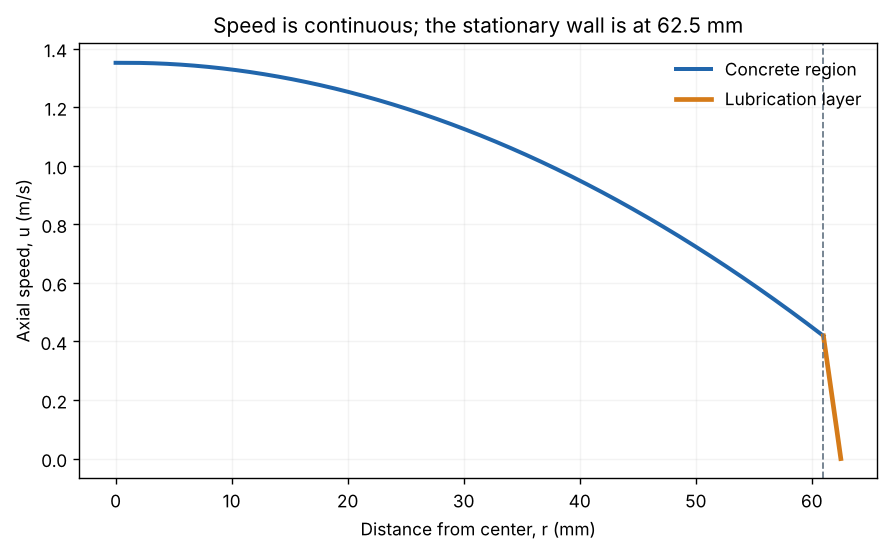

In [20]:
# Make a velocity plot with separate traces to reveal the material interface.
fig, ax = plt.subplots(figsize=(7.0, 4.3), layout="constrained")
# Plot the center-to-interface concrete speed using millimetres on the x-axis.
ax.plot(1000 * profile["core_r"], profile["core_speed"], color=palette["blue"], lw=2.3, label="Concrete region")
# Plot the thin interface-to-wall layer speed using the same speed scale.
ax.plot(1000 * profile["layer_r"], profile["layer_speed"], color=palette["orange"], lw=2.7, label="Lubrication layer")
# Mark the interface radius to relate the speed profile to the earlier sketch.
ax.axvline(1000 * interface_radius_m, color=palette["grey"], lw=1.0, ls="--")
# Label axes and model case; the core's broad plateau denotes a tiny plug near r=0.
ax.set(xlabel="Distance from center, r (mm)", ylabel="Axial speed, u (m/s)", title="Speed is continuous; the stationary wall is at 62.5 mm")
# Add a restrained grid for reading the narrow outer-layer interval.
ax.grid(alpha=0.15)
# Identify curves from the material region rather than color alone.
ax.legend(frameon=False, loc="upper right")
# Save and embed the original full-width velocity comparison.
finish_figure(fig, "04_velocity_profile")

**Figure 4.** Nearly the entire concrete region has appreciable speed because it is carried along by the moving interface. The layer's speed falls to zero at the true wall. The tiny plug for the chosen low yield stress is difficult to see at the scale of the whole pipe.

**A useful surprise:** in this example the thin layer itself transports only about 0.44 m³/h, yet its presence increases the *total* modeled rate from about 21.60 to 37.68 m³/h at the same pressure loss. Its main effect is changing the speed of the much larger concrete region, not transporting most of the concrete inside the narrow annulus.

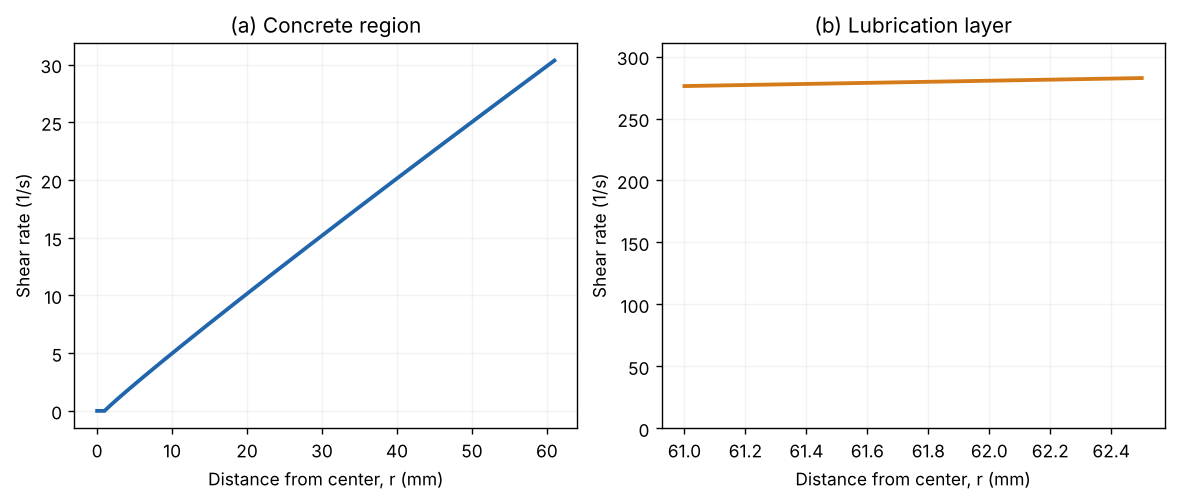

In [21]:
# Use separate axes to make small core and large LL shear rates both readable.
fig, axes = plt.subplots(1, 2, figsize=(9.3, 3.9), layout="constrained")
# Draw core shear rate all the way to the interface, including the zero-rate plug.
axes[0].plot(1000 * profile["core_r"], profile["core_rate"], color=palette["blue"], lw=2.2)
# Draw LL shear rate on its true millimetre-wide interval rather than stretching data.
axes[1].plot(1000 * profile["layer_r"], profile["layer_rate"], color=palette["orange"], lw=2.2)
# Label the core panel with both the location and the measured quantity.
axes[0].set(xlabel="Distance from center, r (mm)", ylabel="Shear rate (1/s)", title="(a) Concrete region")
# Label the outer-layer panel without forcing the core's lower vertical scale on it.
axes[1].set(xlabel="Distance from center, r (mm)", ylabel="Shear rate (1/s)", title="(b) Lubrication layer")
# Start the LL shear-rate axis at zero so its small relative change is not exaggerated.
axes[1].set_ylim(0.0, 1.10 * np.max(profile["layer_rate"]))
# Apply the same light grid to both panels of the comparison.
for ax in axes:
    # Allow readable coordinates without implying a smooth bridge between fluids.
    ax.grid(alpha=0.15)
# Save and show the distinct local slopes for the two regions.
finish_figure(fig, "05_shear_rate_two_scales")

**Figure 5.** The rate of change of speed can jump at the sharp model interface because the materials differ, while the speed itself stays continuous. The layer may have a much higher shear rate even though it is narrow, as in Figure 3 of the paper.

## 8. Change one condition: pressure loss

Increasing $G$ increases radial stress. We will generate an **output curve**, $Q$ versus $G$, for the same pipe under three assumptions: HB concrete without LL, a Bingham two-region model ($n=1$ for each material), and the paper's HB two-region example ($n=1.05$). Holding geometry and all other numerical parameters fixed isolates the role of the model choice. A numerical value for $K$ has different units when $n$ changes, so the Bingham comparison is a **specific parameter scenario**, not a controlled experimental test of the exponent alone. We handle the latter more carefully in Section 11.

In [22]:
# Make a Bingham variant with the same illustrative numerical K and n set to 1.
core_bingham = {"tau0_pa": 30.0, "K_pa_s_n": 50.0, "n": 1.0}
# Make a corresponding linear variant for the material in the layer.
layer_bingham = {"tau0_pa": 1.0, "K_pa_s_n": 5.0, "n": 1.0}
# Choose increasing pressure losses per unit pipe length in kPa/m for readable axes.
gradient_grid_kpa_m = np.linspace(10.0, 100.0, 91)
# Convert every input to Pa/m before passing it into a function with SI units.
gradient_grid_pa_m = 1000.0 * gradient_grid_kpa_m
# Predict flow rate without LL for each pressure gradient, in m³/h.
no_layer_curve_m3_h = np.array([3600.0 * two_layer_hb_flow_m3_s(g, pipe_radius_m, 0.0, core_hb, layer_hb) for g in gradient_grid_pa_m])
# Predict flow with a Bingham pair of materials for the same gradients.
bingham_curve_m3_h = np.array([3600.0 * two_layer_hb_flow_m3_s(g, pipe_radius_m, layer_thickness_m, core_bingham, layer_bingham) for g in gradient_grid_pa_m])
# Predict flow with a two-material HB pair for those identical gradients.
hb_curve_m3_h = np.array([3600.0 * two_layer_hb_flow_m3_s(g, pipe_radius_m, layer_thickness_m, core_hb, layer_hb) for g in gradient_grid_pa_m])
# Catch a pressure-unit mistake or an unexpected negative pressure response.
assert np.all(np.diff(hb_curve_m3_h) > 0.0)

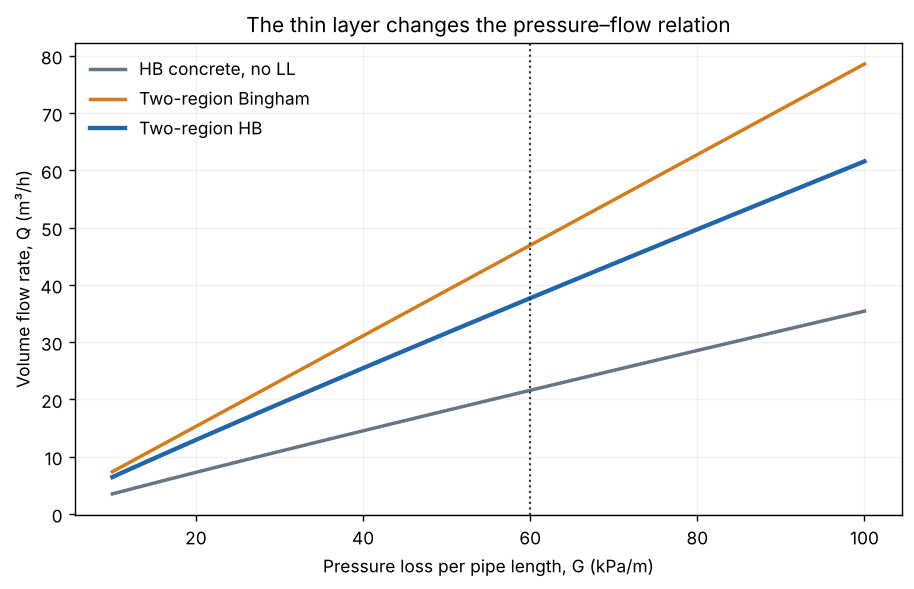

In [23]:
# Set up a legible single-panel comparison with shared axes and units.
fig, ax = plt.subplots(figsize=(7.2, 4.6), layout="constrained")
# Show the no-layer HB baseline so the effect of a layer is visible.
ax.plot(gradient_grid_kpa_m, no_layer_curve_m3_h, color=palette["grey"], lw=2.0, label="HB concrete, no LL")
# Show the two-region linear Bingham special case in a contrasting color.
ax.plot(gradient_grid_kpa_m, bingham_curve_m3_h, color=palette["orange"], lw=2.0, label="Two-region Bingham")
# Show the nonlinear two-region HB case used throughout the main demonstration.
ax.plot(gradient_grid_kpa_m, hb_curve_m3_h, color=palette["blue"], lw=2.5, label="Two-region HB")
# Mark the gradient used in the profile calculations with a discreet line.
ax.axvline(pressure_gradient_pa_m / 1000.0, color=palette["ink"], ls=":", lw=1.2)
# Make both physical quantities and the illustrative comparison explicit.
ax.set(xlabel="Pressure loss per pipe length, G (kPa/m)", ylabel="Volume flow rate, Q (m³/h)", title="The thin layer changes the pressure–flow relation")
# Keep the key profile-comparison region unobstructed by the legend.
ax.legend(frameon=False, loc="upper left")
# Support numerical reading with a subtle background grid.
ax.grid(alpha=0.16)
# Save and embed the three complete model curves.
finish_figure(fig, "06_flow_vs_gradient")

**Figure 6.** The comparison is at identical pressure losses. These predictions are from model parameter sets, not experimental validation. A change in $n$ changes the units of $K$; the model-to-model separation alone does not identify which constitutive law best describes a real mix.

## 9. Change only the layer thickness

Keep $G$, the pipe radius, and *both material laws* fixed. We now vary the assumed LL thickness. In an actual pump, layer thickness can depend on the material and operating conditions; treating it as independently adjustable is a **sensitivity experiment inside this model**. **Predict** how $Q$ should change as the more easily sheared region grows.

In [24]:
# Examine layer thicknesses from zero through five millimetres at fixed G.
thicknesses_mm = np.linspace(0.0, 5.0, 51)
# Convert each millimetre value to SI metres before evaluating the model.
thicknesses_m = thicknesses_mm / 1000.0
# Recalculate the delivery rate for every thickness in cubic metres per hour.
thickness_q_m3_h = np.array([3600.0 * two_layer_hb_flow_m3_s(pressure_gradient_pa_m, pipe_radius_m, ell, core_hb, layer_hb) for ell in thicknesses_m])
# Verify that the curve's zero-thickness limit agrees with the earlier baseline.
assert np.isclose(thickness_q_m3_h[0], 3600.0 * example_no_layer_q)
# Check the expected trend for these particular model parameters.
assert np.all(np.diff(thickness_q_m3_h) > 0.0)

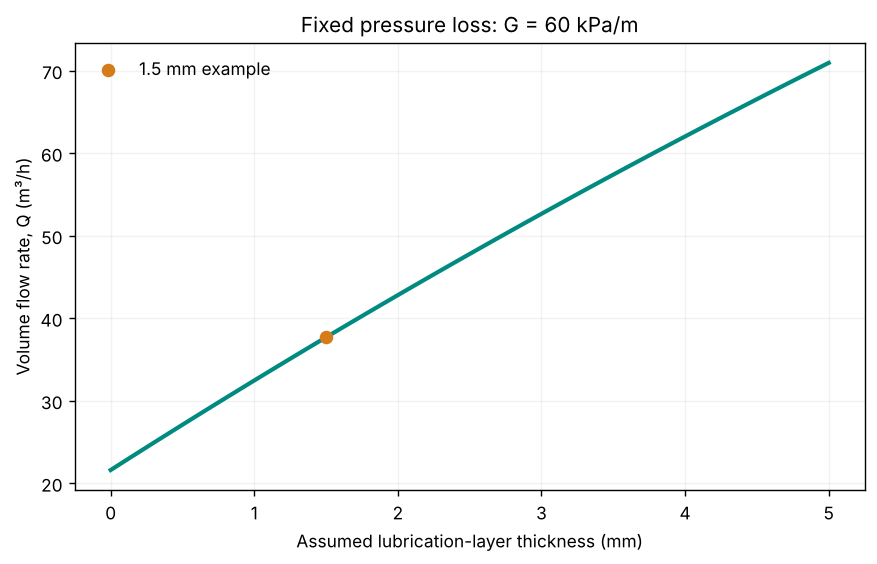

In [25]:
# Draw the thickness experiment using the actual independent variable in mm.
fig, ax = plt.subplots(figsize=(6.9, 4.4), layout="constrained")
# Plot delivery rate across the entire tested thickness range.
ax.plot(thicknesses_mm, thickness_q_m3_h, color=palette["teal"], lw=2.4)
# Mark the original 1.5 mm paper example for orientation.
ax.scatter([1.5], [example_two_layer_q * 3600.0], s=46, color=palette["orange"], zorder=3, label="1.5 mm example")
# State the fixed gradient in the title so the comparison is interpretable.
ax.set(xlabel="Assumed lubrication-layer thickness (mm)", ylabel="Volume flow rate, Q (m³/h)", title="Fixed pressure loss: G = 60 kPa/m")
# Label the highlighted baseline example without visual clutter.
ax.legend(frameon=False, loc="upper left")
# Include a faint grid to read the predicted change in rate.
ax.grid(alpha=0.16)
# Save and show the one-input-at-a-time thickness study.
finish_figure(fig, "07_layer_thickness_sensitivity")

**Figure 7.** The line shows a *conditional model response*. Increasing thickness also reduces the radius of the central material, and those two changes are accounted for together by the same formula. A real LL need not remain homogeneous or keep fixed properties as its thickness varies.

## 10. When does the entire concrete region plug?

At the fixed $60$ kPa/m gradient, the Case II / Case I boundary occurs when $r_{\rm plug}=a$, or $\tau_{0,C}=Ga/2$. Above it, changing the core's yield stress no longer changes its *shear contribution* in this model: the layer can still move the entire core as a plug. Do not mistake a flat part of this curve for zero flow.

In [26]:
# Sweep illustrative bulk yield stresses while holding the layer material fixed.
yield_values_pa = np.linspace(0.0, 2200.0, 111)
# Evaluate the two-region rate independently at each yield stress.
yield_q_m3_h = np.array([3600.0 * two_layer_hb_flow_m3_s(pressure_gradient_pa_m, pipe_radius_m, layer_thickness_m, {"tau0_pa": value, "K_pa_s_n": core_hb["K_pa_s_n"], "n": core_hb["n"]}, layer_hb) for value in yield_values_pa])
# Calculate the threshold for a fully plugged core, in pascals.
case_boundary_pa = pressure_gradient_pa_m * interface_radius_m / 2.0
# Show the threshold and the still-positive high-yield flow.
print(f"Case switch at τ₀,C = {case_boundary_pa:.1f} Pa; high-yield flow = {yield_q_m3_h[-1]:.2f} m³/h")
# Check the model's plug plateau at the last two yield values.
assert np.isclose(yield_q_m3_h[-1], yield_q_m3_h[-2], rtol=1e-12)

Case switch at τ₀,C = 1830.0 Pa; high-yield flow = 18.08 m³/h


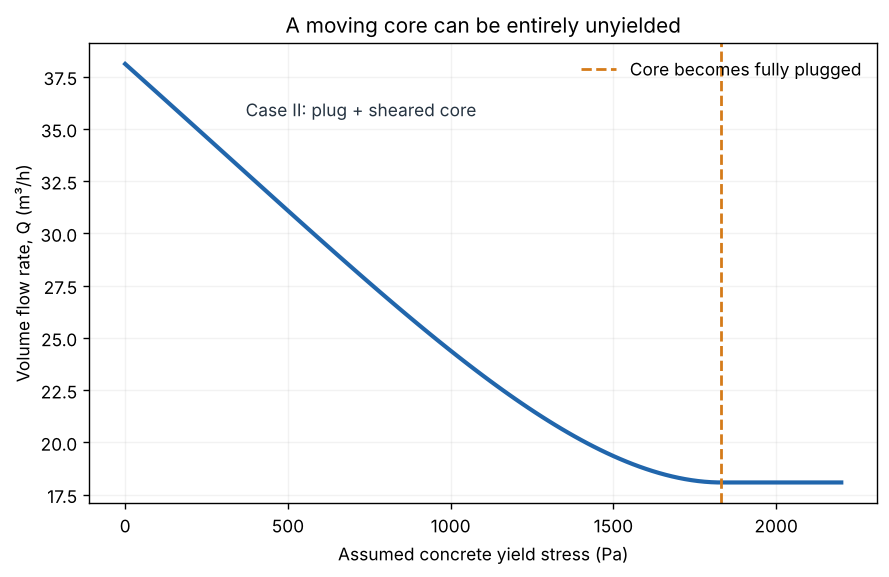

In [27]:
# Present the shearing-to-plug transition on its own well-scaled plot.
fig, ax = plt.subplots(figsize=(7.0, 4.5), layout="constrained")
# Plot the predicted total delivery rate while only core yield stress changes.
ax.plot(yield_values_pa, yield_q_m3_h, color=palette["blue"], lw=2.4)
# Mark the exact transition at which core shear reaches zero.
ax.axvline(case_boundary_pa, color=palette["orange"], ls="--", lw=1.6, label="Core becomes fully plugged")
# Use region labels where they do not obscure the data curve.
ax.text(370, yield_q_m3_h[0] - 2.5, "Case II: plug + sheared core", color=palette["ink"])
# Label both axes and the fixed pressure condition.
ax.set(xlabel="Assumed concrete yield stress (Pa)", ylabel="Volume flow rate, Q (m³/h)", title="A moving core can be entirely unyielded")
# Explain the dashed line with a small unobtrusive legend.
ax.legend(frameon=False, loc="upper right")
# Add a light grid for interpreting the plateau level.
ax.grid(alpha=0.16)
# Save and embed the paper's Case I/II distinction as a new computation.
finish_figure(fig, "08_yield_and_plug_transition")

**Figure 8.** The plotted transition is a mathematical regime change. At the chosen $G$, $R$, and $\ell$, the illustrative 30 Pa mix lies well inside Case II. The model's weak response to small core yield stresses should not be generalized to all pumping conditions.

## 11. Change the shape of the material law carefully

At a selected **reference shear rate** $\dot\gamma_*$, compare material laws that have the same stress $\tau(\dot\gamma_*)$ while varying their exponent $n$. This avoids holding a bare numerical $K$ fixed even though its unit changes from Pa·s$^{n_1}$ to Pa·s$^{n_2}$. If the baseline exponent is $n_0$, set $K_{\rm new}=K_0\dot\gamma_*^{n_0-n_{\rm new}}$. We choose 10 1/s for the concrete and 100 1/s for the layer. Those rates are **teaching reference points**, not fitted measurement data. We compare $n=0.90,1.05,1.20$ separately for each region.

In [28]:
# Construct an HB material whose stress matches a baseline at one shear rate.
def matched_exponent_material(base, new_exponent, reference_rate_s_inv):
    '''Return new HB parameters with equal stress at a chosen reference rate.'''
    # Rescale K so changes in n do not change the stress at the reference rate.
    new_K = base["K_pa_s_n"] * reference_rate_s_inv ** (base["n"] - new_exponent)
    # Preserve the same yield stress while allowing K's unit to follow new n.
    return {"tau0_pa": base["tau0_pa"], "K_pa_s_n": new_K, "n": new_exponent}

# Choose a thinning, baseline, and thickening example in increasing order.
exponents_to_compare = [0.90, 1.05, 1.20]
# Build equal-reference-stress bulk laws at 10 inverse seconds.
core_variants = [matched_exponent_material(core_hb, n_value, 10.0) for n_value in exponents_to_compare]
# Build equal-reference-stress layer laws at 100 inverse seconds.
layer_variants = [matched_exponent_material(layer_hb, n_value, 100.0) for n_value in exponents_to_compare]
# Confirm all bulk variants really meet at the chosen physical reference point.
assert np.allclose([hb_stress_pa(10.0, item) for item in core_variants], hb_stress_pa(10.0, core_hb))
# Confirm the independent set of layer variants meets at its own reference point.
assert np.allclose([hb_stress_pa(100.0, item) for item in layer_variants], hb_stress_pa(100.0, layer_hb))

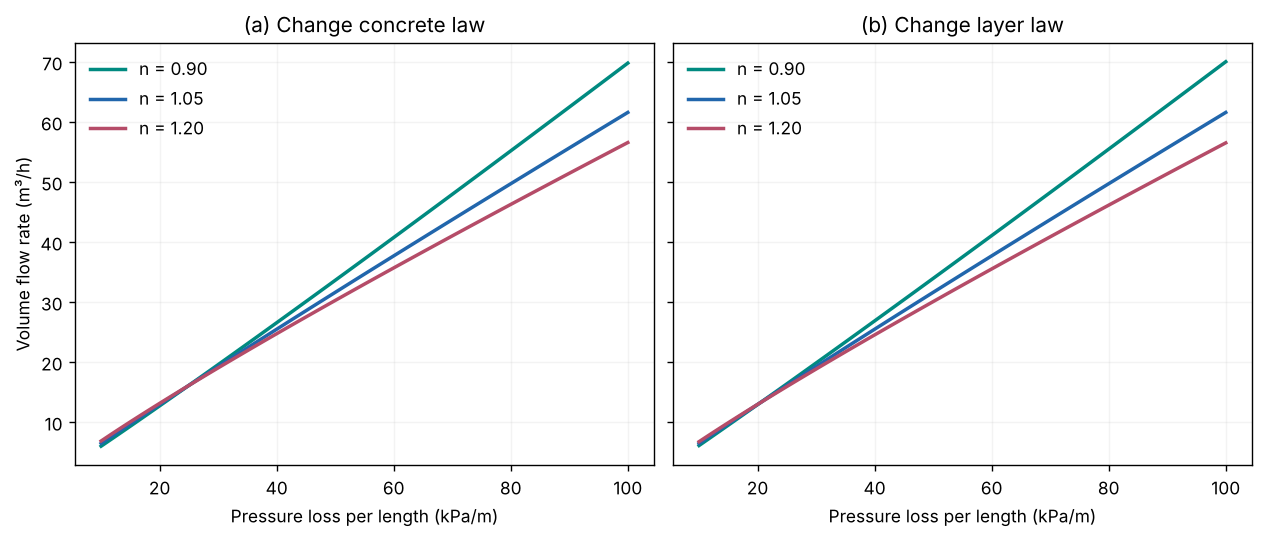

In [29]:
# Create two panels to isolate the exponent of one material at a time.
fig, axes = plt.subplots(1, 2, figsize=(10.0, 4.2), sharey=True, layout="constrained")
# Use three colors with the same meaning in the two panels.
variant_colors = [palette["teal"], palette["blue"], palette["rose"]]
# Pair the chosen exponents and colors for reproducible legend order.
for n_value, core_variant, layer_variant, color in zip(exponents_to_compare, core_variants, layer_variants, variant_colors):
    # Calculate a pressure sweep while changing only the concrete exponent law.
    core_response = [3600 * two_layer_hb_flow_m3_s(g, pipe_radius_m, layer_thickness_m, core_variant, layer_hb) for g in gradient_grid_pa_m]
    # Show each controlled concrete variant in the first panel.
    axes[0].plot(gradient_grid_kpa_m, core_response, color=color, lw=2.0, label=f"n = {n_value:.2f}")
    # Calculate a new sweep while changing only the layer exponent law.
    layer_response = [3600 * two_layer_hb_flow_m3_s(g, pipe_radius_m, layer_thickness_m, core_hb, layer_variant) for g in gradient_grid_pa_m]
    # Show the corresponding controlled layer variant in the second panel.
    axes[1].plot(gradient_grid_kpa_m, layer_response, color=color, lw=2.0, label=f"n = {n_value:.2f}")
# Explain exactly which region differs in the left experiment.
axes[0].set(xlabel="Pressure loss per length (kPa/m)", ylabel="Volume flow rate (m³/h)", title="(a) Change concrete law")
# Explain exactly which region differs in the right experiment.
axes[1].set(xlabel="Pressure loss per length (kPa/m)", title="(b) Change layer law")
# Apply unobtrusive labels and grids to each controlled scenario.
for ax in axes:
    # Link plotted colors to their HB exponent values.
    ax.legend(frameon=False, loc="upper left")
    # Leave data visible while still allowing comparisons at a chosen G.
    ax.grid(alpha=0.15)
# Export the matched-reference-stress comparison.
finish_figure(fig, "09_exponent_sensitivity")

**Figure 9.** A fluid law calibrated at one shear rate can diverge from another law at different rates. The curves need not remain ordered over *every* pressure because the material laws cross at their selected reference rates. This is a reason to examine the shear-rate range relevant to the application, as the paper discusses; it is not evidence that one law is always more accurate.

## 12. Reverse the calculation: what pressure is needed?

On a building site an engineer might specify a delivery rate first. Then the pressure loss $G$ is unknown. Because $Q(G)$ rises for these parameters, we can find $G$ using **bisection**: pick a range that brackets the target, halve it repeatedly, and keep the half in which the answer lies. This is a beginner-friendly version of the root-finding step proposed in the paper. The computed pressure is for the modeled straight pipe alone; fittings, bends, transients, and equipment constraints are outside this calculation.

In [30]:
# Solve the model's inverse problem using only a loop and repeated halving.
def gradient_for_target_q_pa_m(target_q_m3_s, radius_m, thickness_m, core, layer):
    '''Find model pressure loss per length (Pa/m) for a positive target Q.'''
    # A positive requested rate is required for this simple bracketing method.
    assert target_q_m3_s > 0.0
    # Begin with no pressure loss at the lower end of the search range.
    lower_pa_m = 0.0
    # Start an upper guess that the code may enlarge if needed.
    upper_pa_m = 1000.0
    # Double the upper pressure until its predicted rate exceeds the target.
    while two_layer_hb_flow_m3_s(upper_pa_m, radius_m, thickness_m, core, layer) < target_q_m3_s:
        # Increase the pressure bound instead of guessing the answer in advance.
        upper_pa_m *= 2.0
        # Stop an impossible or badly configured search with a useful message.
        if upper_pa_m > 1e9:
            # Indicate that the chosen target was not bracketed in the safety range.
            raise ValueError("Target not bracketed below 1e9 Pa/m")
    # Refine the bracket enough that rounding to practical units is stable.
    for _ in range(70):
        # Cut the current pressure interval into two equal halves.
        middle_pa_m = (lower_pa_m + upper_pa_m) / 2.0
        # Compare the model prediction at the midpoint with the desired rate.
        if two_layer_hb_flow_m3_s(middle_pa_m, radius_m, thickness_m, core, layer) < target_q_m3_s:
            # Keep the upper half when midpoint flow is still too small.
            lower_pa_m = middle_pa_m
        # Otherwise the answer lies at or below the tested midpoint.
        else:
            # Keep the lower half of the pressure bracket.
            upper_pa_m = middle_pa_m
    # Report the midpoint of the final very narrow pressure interval.
    return (lower_pa_m + upper_pa_m) / 2.0

In [31]:
# Request an illustrative delivery rate of 36 m³/h and convert to m³/s.
target_q_m3_s = 36.0 / 3600.0
# Set a 20 m straight horizontal pipe length for a pressure example.
example_pipe_length_m = 20.0
# Find the required pressure gradient for the paper's 1.5 mm LL scenario.
gradient_with_layer_pa_m = gradient_for_target_q_pa_m(target_q_m3_s, pipe_radius_m, layer_thickness_m, core_hb, layer_hb)
# Find the gradient for a pipe without a layer under otherwise matching inputs.
gradient_without_layer_pa_m = gradient_for_target_q_pa_m(target_q_m3_s, pipe_radius_m, 0.0, core_hb, layer_hb)
# Turn gradient times length into horizontal-pipe pressure loss, in MPa.
horizontal_loss_mpa = gradient_with_layer_pa_m * example_pipe_length_m / 1e6
# Report both gradients and state the assumed straight-pipe length.
print(f"For 36 m³/h: with LL {gradient_with_layer_pa_m / 1000:.2f} kPa/m; without LL {gradient_without_layer_pa_m / 1000:.2f} kPa/m")
# Show the horizontal model pressure loss across the illustrative 20 m length.
print(f"With LL, 20 m horizontal straight-pipe loss = {horizontal_loss_mpa:.3f} MPa")
# Substitute the root back into the forward model to check the requested output.
assert np.isclose(two_layer_hb_flow_m3_s(gradient_with_layer_pa_m, pipe_radius_m, layer_thickness_m, core_hb, layer_hb), target_q_m3_s, rtol=1e-10)
# Confirm the layer reduces modeled pressure for this particular target and inputs.
assert gradient_with_layer_pa_m < gradient_without_layer_pa_m

For 36 m³/h: with LL 57.22 kPa/m; without LL 101.70 kPa/m
With LL, 20 m horizontal straight-pipe loss = 1.144 MPa


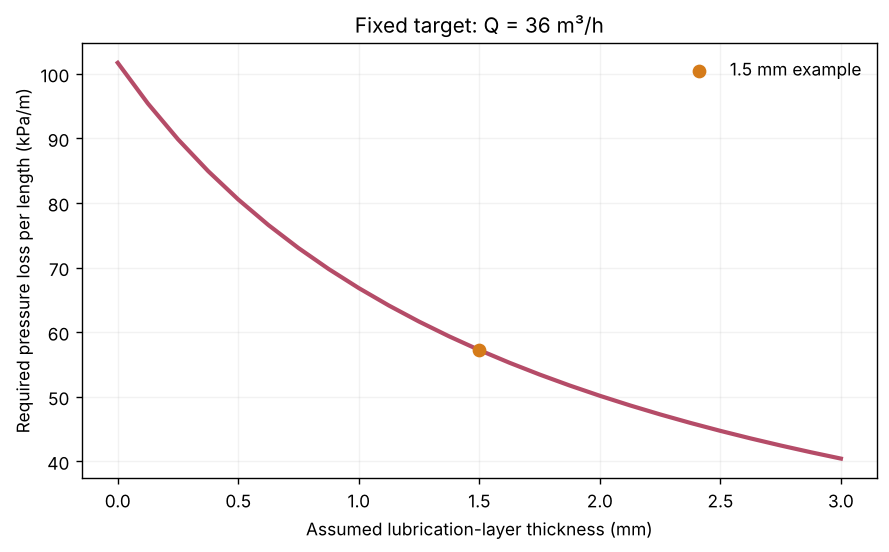

In [32]:
# Choose layer thicknesses in a limited range to inspect required pressure.
design_thickness_mm = np.linspace(0.0, 3.0, 25)
# Solve the inverse problem for the same target flow at each thickness.
design_gradients_kpa_m = np.array([gradient_for_target_q_pa_m(target_q_m3_s, pipe_radius_m, ell_mm / 1000.0, core_hb, layer_hb) / 1000.0 for ell_mm in design_thickness_mm])
# Prepare a pressure-demand plot with an unambiguous fixed target.
fig, ax = plt.subplots(figsize=(7.0, 4.3), layout="constrained")
# Draw the gradient demanded by the model over the tested layer sizes.
ax.plot(design_thickness_mm, design_gradients_kpa_m, color=palette["rose"], lw=2.4)
# Mark the original example and its computed inverse-model result.
ax.scatter([1.5], [gradient_with_layer_pa_m / 1000], color=palette["orange"], s=48, zorder=3, label="1.5 mm example")
# State the invariant target and quantities in the plot itself.
ax.set(xlabel="Assumed lubrication-layer thickness (mm)", ylabel="Required pressure loss per length (kPa/m)", title="Fixed target: Q = 36 m³/h")
# Add a small label for the highlighted baseline condition.
ax.legend(frameon=False, loc="upper right")
# Keep the grid restrained for publication-style readability.
ax.grid(alpha=0.16)
# Export the inverse-engineering sensitivity figure.
finish_figure(fig, "10_pressure_required_for_target")

**Figure 10.** At fixed desired delivery rate, the modeled pressure changes as the *assumed* layer thickness changes. The inverse search is checked by inserting its result back into the forward model. A pressure-loss estimate for one idealized straight pipe segment is not a full pump-selection calculation.

## 13. Optional advanced extension: another material law

The paper also treats a **modified Bingham** material, Eq. (4): $\tau=\tau_0+\mu_p\dot\gamma+A_2\dot\gamma^2$ above yield, with no shear below yield. Units are $\mu_p$: Pa·s and $A_2$: Pa·s². The positive $A_2$ values below create shear thickening; $A_2=0$ recovers ordinary Bingham. Solving the quadratic for $\dot\gamma$ using the stable form

$$\dot\gamma=\frac{2(\tau-\tau_0)}{\mu_p+\sqrt{\mu_p^2+4A_2(\tau-\tau_0)}}$$

lets us reuse the shear-rate integral rather than transcribing the paper's lengthy Eq. (17). This section uses *illustrative material parameters from the paper's Figure 8*; the HB and modified-Bingham numbers below are **not joint fits to the same measured dataset**, so their difference is a model demonstration, not an accuracy ranking. Only $A_2\ge0$ is implemented here: negative $A_2$ needs a restricted monotone range and additional care.

In [33]:
# Record the paper's illustrative modified-Bingham concrete parameters in SI units.
core_mb = {"tau0_pa": 30.0, "mu_pa_s": 50.0, "A2_pa_s2": 0.5}
# Record the corresponding illustrative layer parameters, including a positive A2.
layer_mb = {"tau0_pa": 1.0, "mu_pa_s": 5.0, "A2_pa_s2": 0.01}
# Implement the stable inverse quadratic law for positive model coefficients.
def mb_shear_rate_s_inv(stress_pa_value, material):
    '''Return modified-Bingham shear rate (1/s) for A2 >= 0.'''
    # Convert scalar or vector stress into an array-compatible numeric object.
    stress = np.asarray(stress_pa_value, dtype=float)
    # Enforce no shear below yield by clipping the stress excess at zero.
    excess_pa = np.maximum(stress - material["tau0_pa"], 0.0)
    # Form a nonnegative discriminant for the physically increasing branch.
    discriminant = material["mu_pa_s"] ** 2 + 4.0 * material["A2_pa_s2"] * excess_pa
    # Use the rationalized quadratic solution, which also handles A2 = 0.
    return 2.0 * excess_pa / (material["mu_pa_s"] + np.sqrt(discriminant))

# Make a Bingham limit with identical yield stress and viscosity for an independent check.
mb_as_bingham = {"tau0_pa": 30.0, "mu_pa_s": 50.0, "A2_pa_s2": 0.0}
# Test a stress above yield where the expected Bingham shear rate is known.
assert np.isclose(mb_shear_rate_s_inv(80.0, mb_as_bingham), 1.0)
# Test the separate no-shear behavior below the material's yield stress.
assert mb_shear_rate_s_inv(20.0, mb_as_bingham) == 0.0

In [34]:
# Generalize the earlier shear-rate quadrature to accept either material law.
def two_region_integral_m3_s(g_pa_m, radius_m, ell_m, core, layer, core_law, layer_law, points=2001):
    '''Numerically integrate a two-material pipe for two inverse stress laws.'''
    # Place the shared interface at radius minus outer-layer thickness.
    interface_m = radius_m - ell_m
    # Grid the concrete region without mixing its law with the LL law.
    core_r = np.linspace(0.0, interface_m, points)
    # Grid the layer separately so a constitutive jump stays at its endpoint.
    layer_r = np.linspace(interface_m, radius_m, points)
    # Apply the chosen inverse stress law to the concrete stress values.
    core_rate = core_law(g_pa_m * core_r / 2.0, core)
    # Apply the chosen inverse stress law to the outer-layer stress values.
    layer_rate = layer_law(g_pa_m * layer_r / 2.0, layer)
    # Integrate the two nonoverlapping radius-squared weighted contributions.
    return np.pi * (np.trapezoid(core_rate * core_r**2, core_r) + np.trapezoid(layer_rate * layer_r**2, layer_r))

# Test the general integrator against the paper's independent exact HB result.
general_hb_q = two_region_integral_m3_s(pressure_gradient_pa_m, pipe_radius_m, layer_thickness_m, core_hb, layer_hb, hb_shear_rate_s_inv, hb_shear_rate_s_inv)
# Check that passing both HB functions recovers the earlier closed-form rate.
assert np.isclose(general_hb_q, example_two_layer_q, rtol=2e-6)
# Calculate the two-region modified-Bingham result using the *same* stress balance.
example_mb_q = two_region_integral_m3_s(pressure_gradient_pa_m, pipe_radius_m, layer_thickness_m, core_mb, layer_mb, mb_shear_rate_s_inv, mb_shear_rate_s_inv)
# Explain the numerical result without treating it as measured performance.
print(f"Two-region HB: {example_two_layer_q * 3600:.2f} m³/h; modified Bingham: {example_mb_q * 3600:.2f} m³/h")
# Recover the analytic two-region Bingham limit when both quadratic terms vanish.
assert np.isclose(two_region_integral_m3_s(pressure_gradient_pa_m, pipe_radius_m, layer_thickness_m, mb_as_bingham, {"tau0_pa": 1.0, "mu_pa_s": 5.0, "A2_pa_s2": 0.0}, mb_shear_rate_s_inv, mb_shear_rate_s_inv), two_layer_hb_flow_m3_s(pressure_gradient_pa_m, pipe_radius_m, layer_thickness_m, core_bingham, layer_bingham), rtol=2e-6)

Two-region HB: 37.68 m³/h; modified Bingham: 34.70 m³/h


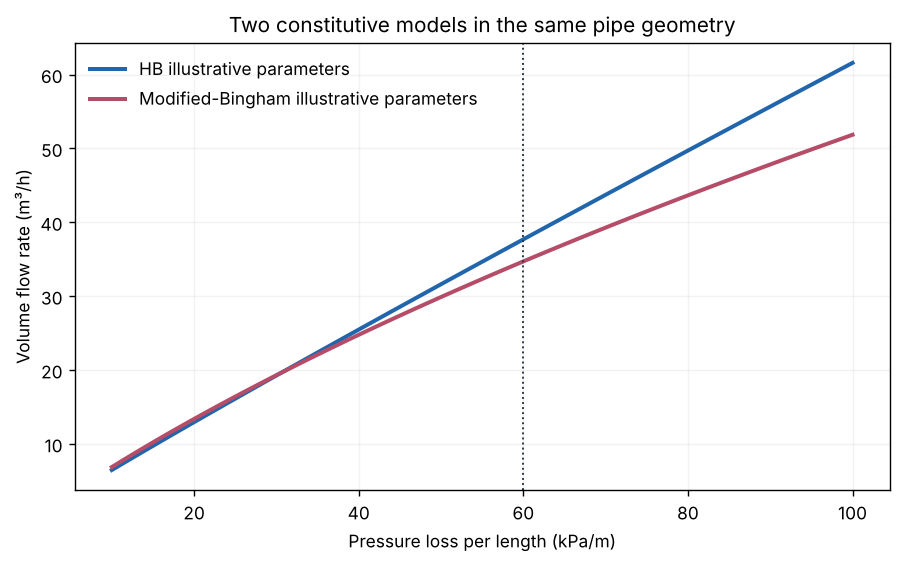

In [35]:
# Evaluate the modified-Bingham scenario over the already defined gradients.
mb_curve_m3_h = np.array([3600 * two_region_integral_m3_s(g, pipe_radius_m, layer_thickness_m, core_mb, layer_mb, mb_shear_rate_s_inv, mb_shear_rate_s_inv, points=1001) for g in gradient_grid_pa_m])
# Set up the model comparison on identical Q and G axes.
fig, ax = plt.subplots(figsize=(7.1, 4.4), layout="constrained")
# Draw the HB example using the closed-form results calculated earlier.
ax.plot(gradient_grid_kpa_m, hb_curve_m3_h, color=palette["blue"], lw=2.3, label="HB illustrative parameters")
# Draw the distinct modified-Bingham scenario with its specified coefficients.
ax.plot(gradient_grid_kpa_m, mb_curve_m3_h, color=palette["rose"], lw=2.3, label="Modified-Bingham illustrative parameters")
# Mark the example's pressure gradient on the same common scale.
ax.axvline(60.0, ls=":", lw=1.1, color=palette["ink"])
# State axes, units, and the fact that this is a material-law comparison.
ax.set(xlabel="Pressure loss per length (kPa/m)", ylabel="Volume flow rate (m³/h)", title="Two constitutive models in the same pipe geometry")
# Distinguish the two material model scenarios clearly without dense annotation.
ax.legend(frameon=False, loc="upper left")
# Use a subdued grid to read output values without obscuring the lines.
ax.grid(alpha=0.16)
# Save and embed the optional second-model comparison.
finish_figure(fig, "11_hb_and_modified_bingham")

**Figure 11.** Both constitutive laws are handled with the same radial force balance and geometric integration. Differences here show sensitivity to *both chosen law and parameter set*. The paper emphasizes that constitutive measurements may cover a narrower shear-rate range than actual pumping; extrapolation needs independent evidence.

## 14. Optional advanced extension: test a thin-layer approximation

An intuitive approximation treats the shear rate throughout the thin layer as equal to its wall value: $u_{\rm interface}\approx\ell\dot\gamma(R)$. The exact speed gain is $\int_a^R\dot\gamma(r)dr$. Because $\tau(r)=Gr/2$ increases toward the wall, the HB shear rate in a yielded layer rises slightly there. For positive layer thickness, the wall-rate estimate **overpredicts interface speed** in this model. This tests the physical intuition behind a simplification discussed with Kaplan's approach in the paper's Section 3.4; it is *not* a transcription of the paper's full Kaplan flow-rate equation.

In [36]:
# Compute the velocity gained across the actual LL from the separate profile.
exact_interface_speed_m_s = profile["layer_speed"][0]
# Evaluate the local layer shear rate at the stationary pipe wall.
wall_layer_rate_s_inv = hb_shear_rate_s_inv(wall_stress_pa, layer_hb)
# Approximate the velocity gain by taking the wall rate to be uniform in LL.
wall_rate_estimate_m_s = layer_thickness_m * wall_layer_rate_s_inv
# Report the comparison in metres per second and its relative overestimate.
print(f"Exact interface speed = {exact_interface_speed_m_s:.5f} m/s; wall-rate estimate = {wall_rate_estimate_m_s:.5f} m/s")
# Quantify error relative to the separately integrated interface speed.
print(f"Wall-rate interface-speed overestimate: {100 * (wall_rate_estimate_m_s / exact_interface_speed_m_s - 1):.2f}%")
# Check the expected direction using the increasing LL shear-rate profile.
assert wall_rate_estimate_m_s > exact_interface_speed_m_s

Exact interface speed = 0.41911 m/s; wall-rate estimate = 0.42396 m/s
Wall-rate interface-speed overestimate: 1.16%


## What we learned—and what we did not calculate

1. Force balance gives $\tau(r)=Gr/2$ in the steady straight-pipe model, even when material properties differ across the radius.
2. A low-shear-resistance outer layer can carry a central concrete region: a small layer thickness can have a substantial modeled effect on $Q$.
3. The same code distinguishes Case I (fully plugged concrete core) and Case II (plug plus sheared concrete core). A plug can move; zero shear rate does not mean zero speed.
4. We checked the HB result with a Newtonian limit, a Bingham limit, a separate shear-rate integral, and a separate velocity-ring integral. Root finding was checked by substitution back into the forward model.

**Model limits.** The paper assumes steady, laminar, fully developed, isothermal, effectively incompressible flow in a straight constant-radius pipe; homogeneous, time-independent properties within each region; a fixed layer thickness; equal-density simplification; no wall slip and continuous interface speed. The real lubrication layer can form during pumping, vary gradually, depend on operating conditions, and change with time. The model omits thixotropy, elasticity, particle-scale migration dynamics, bends, fittings, and transient pump cycles. A calculated pressure is therefore conditional on the assumed material parameters and geometry, not a safety or equipment recommendation.

**Height and gravity.** The paper defines $\mathcal P=p+\rho gh$. For a rise from height $h_0$ to $h_L$ with one effective density, the required static pressure difference is $p_0-p_L=GL+\rho g(h_L-h_0)$. Our numerical examples are *horizontal*, so the height term is zero. The equal-density assumption and extra losses would need review before using this expression for a real installation.

### Predict → change → explain

1. **By hand:** Recalculate the stress at the wall if the radius doubles while $G$ stays fixed. Run the relevant cell with the new radius; explain why the numerical value changed.
2. **One variable:** Change the layer thickness from 1.5 to 0.5 mm and predict the effect on $Q$ at 60 kPa/m. Check with `two_layer_hb_flow_m3_s`; give the answer in m³/h.
3. **A plug still moves:** Set the bulk yield stress to 2000 Pa. Predict which of the two terms in the analytical decomposition vanishes. Check that the total flow rate remains positive and inspect the revised velocity profile.
4. **Validation:** Reduce the integration `points` from 2001 to 101, then increase it to 4001. Record the difference from the closed-form solution and explain why refining a grid helps assess numerical error.
5. **Design question:** Choose a different target flow, rerun the bisection solver, and check the new $Q(G)$ by substitution. State the modeled pipe length and the pressure units.
6. **Advanced:** For the same model material, set $A_2=0$ in the modified-Bingham law and compare with an HB law having $n=1$. Explain why their inverse shear laws agree. Examine only $A_2\ge0$ with the implementation above.

**Source:** Zhaidarbek, Tleubek, Berdibek & Wang (2023), *Cement and Concrete Research* **163**, 107035, [doi:10.1016/j.cemconres.2022.107035](https://doi.org/10.1016/j.cemconres.2022.107035). The notebook uses its Eqs. (3), (4), (8)–(16), Appendix A, and illustrative Figure 3–8 parameters; figures and Python code here are newly made for introductory teaching. Consult the paper for its full derivation and experimental context. No measurements are bundled with this notebook.